# Short-Horizon Predictive Analysis of Order Book Signals

This notebook explores whether order book signals predict short-horizon midprice movements in CME E-mini S&P 500 (ES) futures.

Using cleaned order book data from 1 day, October 8, 2026, we evaluate order book imbalance (OBI), microprice, signal decay, and preliminary execution feasibility.

This is an initial single-session analysis intended to establish the research methodology before extending the analysis across multiple trading days.

### 1. Data Loading and Feature Construction

Load cleaned ES futures order book data using the project's existing data pipeline.

Calculate midprice and order book imbalance (OBI), then sample the latest observation from each minute for preliminary analysis.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from finm37000_grp2 import config
from finm37000_grp2.features import (
    calculate_microprice,
    calculate_midprice,
    calculate_obi,
    calculate_spread,
)

# Load cleaned development sample
df = pd.read_parquet(config.PROCESSED_DIR / "ES" / "2026-10-08.parquet")
# Exclude locked quotes and contract-roll observations
df = df.loc[~df["locked"] & ~df["roll"]].copy()

# Calculate order-book features
df["midprice"] = calculate_midprice(df["bid_px"], df["ask_px"])
df["obi"] = calculate_obi(df["bid_sz"], df["ask_sz"])

# Take the last available observation each minute
minute_df = df.resample("1min").last().dropna(subset=["midprice", "obi"])

print(minute_df[["midprice", "obi"]].head())
print(f"\nNumber of minute observations: {len(minute_df)}")

                           midprice       obi
ts_event                                     
2026-10-08 13:30:00+00:00  7824.875  0.419355
2026-10-08 13:31:00+00:00  7828.125  0.022222
2026-10-08 13:32:00+00:00  7827.875 -0.309091
2026-10-08 13:33:00+00:00  7829.375  0.142857
2026-10-08 13:34:00+00:00  7831.875  0.125000

Number of minute observations: 405


### 2. Initial Predictability Test: One-Minute Returns

Evaluate the relationship between current OBI and the subsequent one-minute midprice return.

This provides an initial measure of whether order book imbalance contains predictive information about future price movements.

**Research Question:** RQ1 — Predictability

In [2]:
# Calculate the return over the next minute
minute_df["future_return"] = minute_df["midprice"].shift(-1) / minute_df["midprice"] - 1

# Remove the final row, which has no future return
analysis_df = minute_df.dropna(subset=["future_return"]).copy()

print(analysis_df[["midprice", "obi", "future_return"]].head())

# Correlation between current OBI and next-minute return
correlation = analysis_df["obi"].corr(analysis_df["future_return"])

print(f"\nOBI vs. next-minute return correlation: {correlation:.4f}")
print(f"Number of observations: {len(analysis_df)}")

                           midprice       obi  future_return
ts_event                                                    
2026-10-08 13:30:00+00:00  7824.875  0.419355       0.000415
2026-10-08 13:31:00+00:00  7828.125  0.022222      -0.000032
2026-10-08 13:32:00+00:00  7827.875 -0.309091       0.000192
2026-10-08 13:33:00+00:00  7829.375  0.142857       0.000319
2026-10-08 13:34:00+00:00  7831.875  0.125000      -0.000638

OBI vs. next-minute return correlation: 0.0472
Number of observations: 404


### 2.1 Visualizing OBI and Future Returns

Plot OBI against next-minute midprice returns to examine the direction, strength, and dispersion of the predictive relationship.

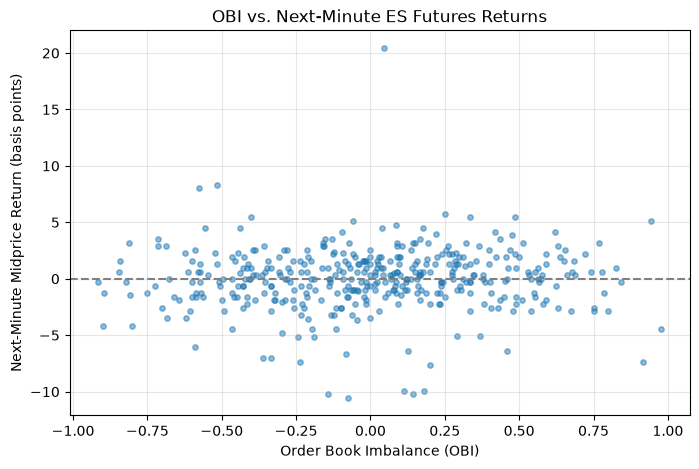

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_df["obi"],
    analysis_df["future_return"] * 10_000,
    alpha=0.5,
    s=15,
)

plt.xlabel("Order Book Imbalance (OBI)")
plt.ylabel("Next-Minute Midprice Return (basis points)")
plt.title("OBI vs. Next-Minute ES Futures Returns")
plt.axhline(0, color="gray", linestyle="--")
plt.grid(alpha=0.3)

plt.show()

### 3. Predictive Returns Across OBI Levels

Divide observations into five OBI groups and compare their average subsequent one-minute returns.

**Research Question:** RQ1 — Predictability

obi_group
Very Low     0.041125
Low         -0.544117
Medium       0.328357
High         0.064280
Very High    0.077158
Name: future_return, dtype: float64


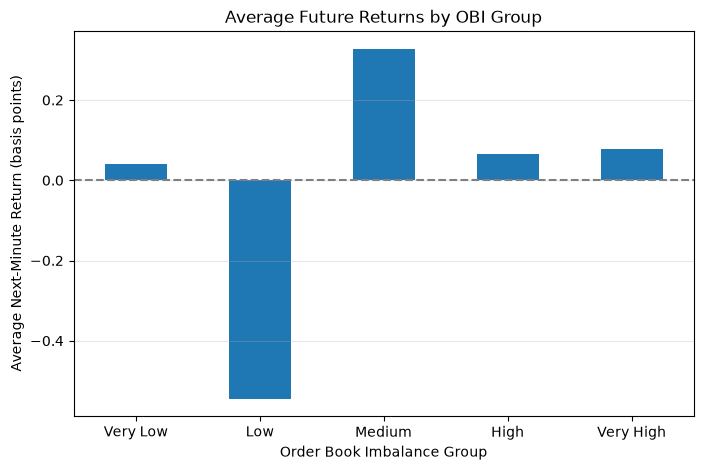

In [4]:
# Divide OBI into five groups, from lowest to highest
analysis_df["obi_group"] = pd.qcut(
    analysis_df["obi"], q=5, labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

# Calculate average next-minute return for each group
group_returns = (
    analysis_df.groupby("obi_group", observed=True)["future_return"].mean() * 10_000
)

print(group_returns)

# Plot average future returns
plt.figure(figsize=(8, 5))

group_returns.plot(kind="bar")

plt.xlabel("Order Book Imbalance Group")
plt.ylabel("Average Next-Minute Return (basis points)")
plt.title("Average Future Returns by OBI Group")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 4. Short-Horizon Predictability and Signal Decay

Evaluate the correlation between OBI and future midprice returns across multiple forecast horizons.

This analysis investigates how quickly predictive information contained in the order book diminishes.

**Research Questions:** RQ1 — Predictability; RQ3 — Alpha Decay

In [5]:
# Keep the latest observation for every second
second_df = df.resample("1s").last()

# Carry forward the last known order book state
second_df[["midprice", "obi"]] = second_df[["midprice", "obi"]].ffill()

# Calculate returns over actual elapsed-second horizons
horizons = [1, 5, 10, 30, 60]
results = []

for h in horizons:
    future_return = second_df["midprice"].shift(-h) / second_df["midprice"] - 1

    correlation = second_df["obi"].corr(future_return)

    results.append({"Horizon (seconds)": h, "Correlation": correlation})

results_df = pd.DataFrame(results)

print(results_df)

   Horizon (seconds)  Correlation
0                  1     0.180875
1                  5     0.078525
2                 10     0.050677
3                 30     0.020579
4                 60     0.018103


### 4.1 Visualizing Predictive Signal Decay

Plot the correlation between OBI and future midprice returns across forecast horizons to illustrate changes in predictive strength over time.

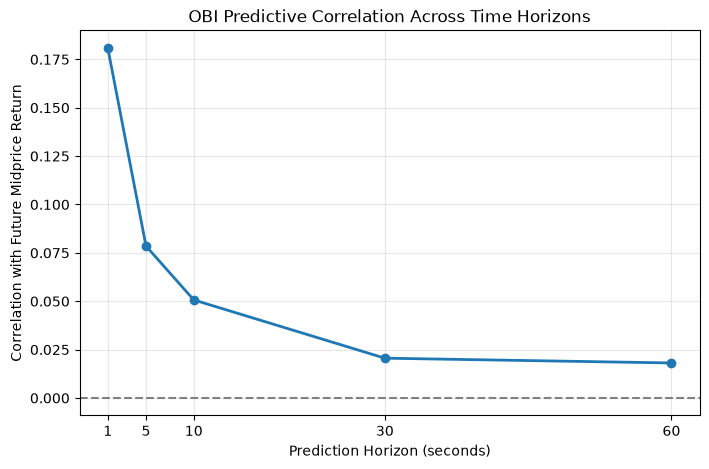

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Horizon (seconds)"],
    results_df["Correlation"],
    marker="o",
    linewidth=2,
)

plt.xlabel("Prediction Horizon (seconds)")
plt.ylabel("Correlation with Future Midprice Return")
plt.title("OBI Predictive Correlation Across Time Horizons")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(horizons)
plt.grid(alpha=0.3)

plt.show()

### 5. Comparing OBI and Microprice Predictive Power

Construct a microprice-based signal and compare its predictive correlations with those of OBI across identical forecast horizons.

This evaluates whether the two order book features exhibit different standalone predictive relationships.

**Research Question:** RQ2 — Incremental Information

In [7]:
# Calculate microprice using existing project function
df["microprice"] = calculate_microprice(
    df["bid_px"],
    df["ask_px"],
    df["bid_sz"],
    df["ask_sz"],
)

# Normalize microprice deviation in basis points
df["microprice_signal"] = (df["microprice"] - df["midprice"]) / df["midprice"] * 10_000

# Sample once per second
signal_df = df[["midprice", "obi", "microprice_signal"]].resample("1s").last().ffill()

# Compare predictive correlations
results = []

for horizon in [1, 5, 10, 30, 60]:
    future_return = signal_df["midprice"].shift(-horizon) / signal_df["midprice"] - 1

    results.append(
        {
            "Horizon": horizon,
            "OBI": signal_df["obi"].corr(future_return),
            "Microprice": signal_df["microprice_signal"].corr(future_return),
        }
    )

comparison_df = pd.DataFrame(results)
print(comparison_df)

   Horizon       OBI  Microprice
0        1  0.180875    0.180830
1        5  0.078525    0.078946
2       10  0.050677    0.050743
3       30  0.020579    0.020727
4       60  0.018103    0.017973


### 5.1 Correlation Between OBI and Microprice

Measure the correlation between the two signals to assess their similarity and potential redundancy.

A high correlation suggests that the signals contain largely overlapping information, although a joint predictive model is needed to test incremental value.

In [8]:
signal_correlation = signal_df["obi"].corr(signal_df["microprice_signal"])

print(f"OBI–Microprice signal correlation: {signal_correlation:.4f}")

OBI–Microprice signal correlation: 0.9988


### 6. Preliminary Execution Feasibility

Compare average absolute future midprice movements against the average quoted bid-ask spread at different prediction horizons.

This provides an initial assessment of whether typical price movements are large enough to warrant further investigation of executable trading strategies.

**Research Question:** RQ4 — Tradability

In [9]:
# Calculate the quoted bid-ask spread using features.py
df["spread"] = calculate_spread(
    df["bid_px"],
    df["ask_px"],
)

# Convert spread to basis points
df["spread_bps"] = df["spread"] / df["midprice"] * 10_000

# Sample the latest observation each second
spread_df = df[["midprice", "spread_bps"]].resample("1s").last().ffill()

# Compare average absolute future returns with the bid-ask spread
spread_results = []

for h in [1, 5, 10, 30, 60]:
    future_return_bps = (
        spread_df["midprice"].shift(-h) / spread_df["midprice"] - 1
    ) * 10_000

    spread_results.append(
        {
            "Horizon": h,
            "Avg Absolute Move (bps)": future_return_bps.abs().mean(),
            "Avg Spread (bps)": spread_df["spread_bps"].mean(),
        }
    )

spread_comparison_df = pd.DataFrame(spread_results)

print(spread_comparison_df.round(4))

   Horizon  Avg Absolute Move (bps)  Avg Spread (bps)
0        1                   0.2102            0.3267
1        5                   0.5248            0.3267
2       10                   0.7476            0.3267
3       30                   1.2984            0.3267
4       60                   1.8945            0.3267


### 7. Preliminary Findings and Next Steps

**Key Findings**

- OBI exhibits its strongest predictive correlation at the one-second horizon (approximately 0.181).
- Predictive correlation decreases substantially across longer horizons, reaching approximately 0.018 at 60 seconds.
- OBI and microprice are highly correlated (approximately 0.999), suggesting substantial overlap between the signals.
- The average one-second absolute midprice movement (0.210 bps) is smaller than the average quoted bid-ask spread (0.327 bps).

**Limitations**

- Results are based on a single trading session.
- Predictive correlations do not establish trading profitability.
- Incremental predictive value has not yet been tested using a joint model.
- Transaction fees, execution delays, and slippage are not included.

**Next Steps**

1. Extend the analysis across multiple trading sessions.
2. Incorporate order flow imbalance (OFI).
3. Evaluate incremental predictive value using combined signals.
4. Develop and backtest trading rules with realistic execution assumptions.